<a href="https://colab.research.google.com/github/shreya252005/ab_testing_repo/blob/main/ab_testing_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

In [2]:
np.random.seed(42)
n_users = 50000
conversion_rate_control = 0.052
conversion_rate_variant = 0.057

In [4]:
data = pd.DataFrame({
    'user_id':range(1,n_users+1),
    'group':np.random.choice(['control','variant'], size=n_users,p=[0.5,0.5])
})

In [5]:
def assign_conversion(row):
  if row['group']=='control':
    return np.random.binomial(1, conversion_rate_control)
  else:
    return np.random.binomial(1, conversion_rate_variant)

data['converted']=data.apply(assign_conversion, axis=1)
print(data.head())
print(data['group'].value_counts())

   user_id    group  converted
0        1  control          0
1        2  variant          0
2        3  variant          0
3        4  variant          0
4        5  control          0
group
control    25053
variant    24947
Name: count, dtype: int64


In [6]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from scipy.stats import chisquare

In [9]:
group_counts=data['group'].value_counts()
observed = [group_counts['control'], group_counts['variant']]
expected=[n_users/2, n_users/2]
chi2_stat, p_value_srm=chisquare(f_obs=observed, f_exp=expected)
print(f"SRM Check - Chi2 p-value: {p_value_srm:.4f} (Should be > 0.05)")

SRM Check - Chi2 p-value: 0.6355 (Should be > 0.05)


In [10]:
summary=data.groupby('group')['converted'].agg(['count','sum','mean'])
summary.columns=['Total Users','Conversions','Conversion Rate']
print(summary)

         Total Users  Conversions  Conversion Rate
group                                             
control        25053         1285         0.051291
variant        24947         1346         0.053954


In [11]:
successes = np.array([summary.loc['control', 'Conversions'], summary.loc['variant', 'Conversions']])
nobs = np.array([summary.loc['control', 'Total Users'], summary.loc['variant', 'Total Users']])
z_stat, p_value = proportions_ztest(successes, nobs)
print(f"\nZ-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")
# from the results, null hypothesis not rejected since p-value>0.05


Z-statistic: -1.3335
P-value: 0.182353


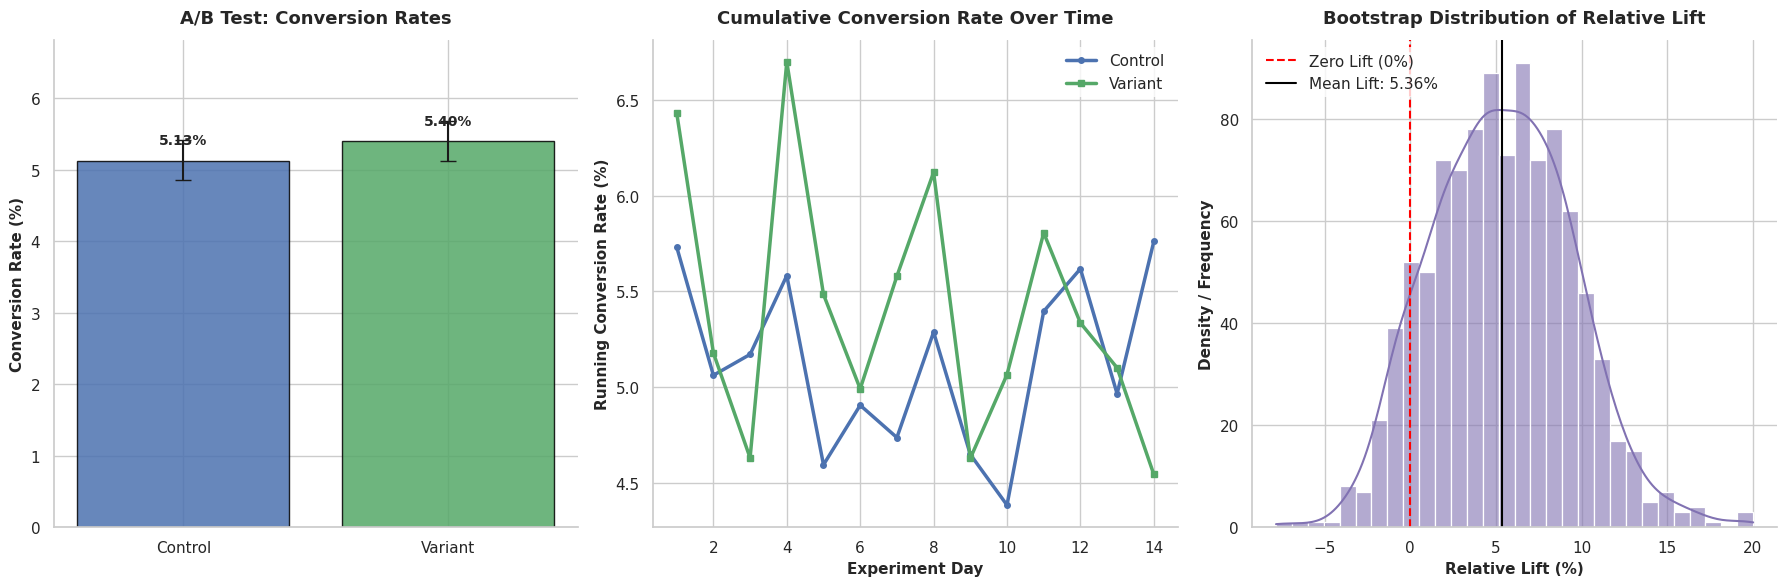

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint
import numpy as np
import pandas as pd

# Set clean styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11})

# Ensure a 'day' column exists for time-series plotting (Simulating a 14-day test)
if 'day' not in data.columns:
    np.random.seed(42)
    data['day'] = np.random.randint(1, 15, size=len(data))

# Set up a 1-row, 3-column subplot layout
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ==========================================
# GRAPH 1: Conversion Rate with 95% CIs
# ==========================================
conf_intervals = []
for group in ['control', 'variant']:
    sub = data[data['group'] == group]
    count = sub['converted'].count()
    nobs = sub['converted'].sum()
    ci_low, ci_upp = proportion_confint(nobs, count, alpha=0.05, method='wilson')
    conf_intervals.append((ci_low, ci_upp))

summary = data.groupby('group')['converted'].agg(['count', 'sum', 'mean']).rename(
    columns={'count': 'Total Users', 'sum': 'Conversions', 'mean': 'Conversion Rate'}
)
summary['ci_low'] = [ci[0] for ci in conf_intervals]
summary['ci_upp'] = [ci[1] for ci in conf_intervals]
summary['yerr_lower'] = summary['Conversion Rate'] - summary['ci_low']
summary['yerr_upper'] = summary['ci_upp'] - summary['Conversion Rate']

bars = axes[0].bar(
    ['Control', 'Variant'],
    summary['Conversion Rate'] * 100,
    yerr=[summary['yerr_lower'] * 100, summary['yerr_upper'] * 100],
    capsize=6,
    color=['#4C72B0', '#55A868'],
    alpha=0.85,
    edgecolor='black',
    linewidth=1
)
axes[0].set_title('A/B Test: Conversion Rates', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Conversion Rate (%)', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, max(summary['ci_upp']) * 100 * 1.2)

for bar in bars:
    height = bar.get_height()
    axes[0].annotate(f'{height:.2f}%',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 10), textcoords="offset points",
                     ha='center', va='bottom', fontweight='bold', fontsize=10)

# ==========================================
# GRAPH 2: Cumulative Conversion Over Time
# ==========================================
# Sort data by day to compute running averages
data_sorted = data.sort_values('day')
cumulative_df = data_sorted.groupby(['day', 'group'])['converted'].mean().unstack()
cumulative_df_pct = cumulative_df * 100

axes[1].plot(cumulative_df_pct.index, cumulative_df_pct['control'], label='Control', color='#4C72B0', linewidth=2.5, marker='o', markersize=4)
axes[1].plot(cumulative_df_pct.index, cumulative_df_pct['variant'], label='Variant', color='#55A868', linewidth=2.5, marker='s', markersize=4)

axes[1].set_title('Cumulative Conversion Rate Over Time', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Experiment Day', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Running Conversion Rate (%)', fontsize=11, fontweight='bold')
axes[1].legend(frameon=True, facecolor='white', edgecolor='none')

# ==========================================
# GRAPH 3: Bootstrap Distribution of Lift
# ==========================================
# Calculate bootstrap distribution of relative lift to show uncertainty
np.random.seed(42)
n_bootstraps = 1000
control_conversions = data[data['group'] == 'control']['converted']
variant_conversions = data[data['group'] == 'variant']['converted']

lift_samples = []
for _ in range(n_bootstraps):
    b_control = np.mean(np.random.choice(control_conversions, size=len(control_conversions), replace=True))
    b_variant = np.mean(np.random.choice(variant_conversions, size=len(variant_conversions), replace=True))
    relative_lift = ((b_variant - b_control) / b_control) * 100
    lift_samples.append(relative_lift)

sns.histplot(lift_samples, kde=True, ax=axes[2], color='#8172B2', bins=30, alpha=0.6)
axes[2].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Lift (0%)')
axes[2].axvline(np.mean(lift_samples), color='black', linestyle='-', linewidth=1.5, label=f'Mean Lift: {np.mean(lift_samples):.2f}%')

axes[2].set_title('Bootstrap Distribution of Relative Lift', fontsize=13, fontweight='bold', pad=12)
axes[2].set_xlabel('Relative Lift (%)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Density / Frequency', fontsize=11, fontweight='bold')
axes[2].legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

# Final Polish
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()